# 01 - Análise exploratória e escolha do subconjunto

Parte 1 do projeto (dados e pipeline). Este notebook:

1. carrega os metadados do BirdCLEF 2025 (`train.csv` + `taxonomy.csv`);
2. descreve a base: classes de animais, coleções, nota de qualidade, gravações por espécie;
3. escolhe o subconjunto do projeto (20 espécies de aves, até 150 gravações cada, só xeno-canto com nota ≥ 4);
4. mede a duração das gravações escolhidas;
5. cria o teste fixo (20%) e os 5 folds, estratificados por espécie e agrupados por gravação.

Saídas: `dados/subconjunto/divisoes.csv` (fora do git) e as figuras em `resultados/eda/`.

In [1]:
# Preparação no Colab (no computador local, rode a partir da raiz do repositório)
import sys, os
EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/birdclef-dl"):
        !git clone -q https://github.com/arbcaio/birdclef-dl.git /content/birdclef-dl
    %cd /content/birdclef-dl
    !pip install -q -e .
    if not os.path.exists("dados/bruto"):
        !ln -s /content/drive/MyDrive/birdclef-dl/dados/bruto dados/bruto
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from birdclef import dados

FIGS = Path("resultados/eda"); FIGS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

meta = dados.carregar_metadados()
print(f"{len(meta)} gravações, {meta.primary_label.nunique()} espécies")
print("colunas:", ", ".join(meta.columns))  # sem mostrar linhas: os dados não podem ser redistribuídos

28564 gravações, 206 espécies
colunas: primary_label, secondary_labels, type, filename, collection, rating, url, latitude, longitude, scientific_name, common_name, author, license, class_name


## Classes de animais e coleções

In [3]:
tab = pd.crosstab(meta["class_name"], meta["collection"], margins=True, margins_name="total")
especies = meta.groupby("class_name")["primary_label"].nunique().rename("espécies")
tab.join(especies).sort_values("total", ascending=False).fillna({"espécies": meta.primary_label.nunique()})

,CSA,XC,iNat,total,espécies
class_name,,,,,
total,162,21204,7198,28564,206.0
Aves,0,21040,6608,27648,146.0
Amphibia,7,147,429,583,34.0
Mammalia,0,17,161,178,9.0
Insecta,155,0,0,155,17.0


A base é dominada por aves. O projeto usa só as aves; anfíbios, mamíferos e insetos ficam de fora.
Só o xeno-canto (XC) tem nota de qualidade (`rating` de 1 a 5); iNaturalist e CSA vêm com 0.

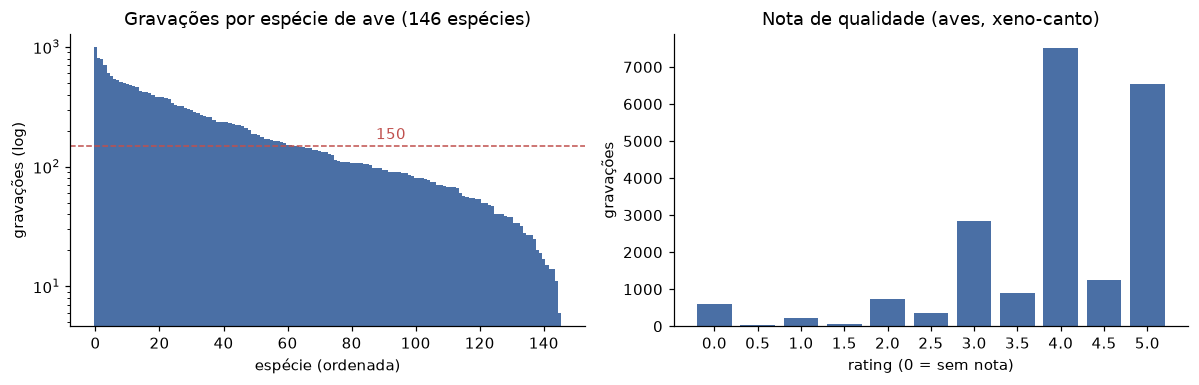

espécies com >= 150 gravações: 62 | mediana: 129


In [4]:
aves = meta[meta["class_name"] == "Aves"]
xc = aves[aves["collection"] == "XC"]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cont = aves["primary_label"].value_counts()
ax[0].bar(range(len(cont)), cont.values, color="#4a6fa5", width=1.0)
ax[0].set_yscale("log"); ax[0].set_xlabel("espécie (ordenada)"); ax[0].set_ylabel("gravações (log)")
ax[0].set_title(f"Gravações por espécie de ave ({len(cont)} espécies)")
ax[0].axhline(150, color="#c0504d", lw=1, ls="--"); ax[0].text(len(cont) * 0.6, 170, "150", color="#c0504d")
notas = xc["rating"].value_counts().sort_index()
ax[1].bar(notas.index.astype(str), notas.values, color="#4a6fa5")
ax[1].set_xlabel("rating (0 = sem nota)"); ax[1].set_ylabel("gravações"); ax[1].set_title("Nota de qualidade (aves, xeno-canto)")
fig.tight_layout(); fig.savefig(FIGS / "gravacoes_e_notas.png", bbox_inches="tight"); plt.show()
print("espécies com >= 150 gravações:", (cont >= 150).sum(), "| mediana:", int(cont.median()))

A distribuição é de cauda longa: poucas espécies concentram muitas gravações e muitas têm poucas.
Por isso o projeto fixa um subconjunto equilibrado em vez de usar todas as espécies.

## Subconjunto do projeto

In [5]:
sub = dados.selecionar_subconjunto(meta, n_especies=20, max_por_especie=150, rating_min=4)
disponiveis = xc[xc["rating"] >= 4]["primary_label"].value_counts()
resumo = (sub.groupby("primary_label")
             .agg(nome=("common_name", "first"), cientifico=("scientific_name", "first"), gravacoes=("filename", "size"))
             .join(disponiveis.rename("disponiveis_r4")))
print(f"{len(sub)} gravações, {sub.primary_label.nunique()} espécies")
resumo.sort_values("disponiveis_r4", ascending=False)

3000 gravações, 20 espécies


,nome,cientifico,gravacoes,disponiveis_r4
primary_label,,,,
grekis,Great Kiskadee,Pitangus sulphuratus,150,387
yeofly1,Yellow-olive Flycatcher,Tolmomyias sulphurescens,150,375
roahaw,Roadside Hawk,Rupornis magnirostris,150,371
wbwwre1,White-breasted Wood-Wren,Henicorhina leucosticta,150,363
trokin,Tropical Kingbird,Tyrannus melancholicus,150,351
banana,Bananaquit,Coereba flaveola,150,348
compau,Common Pauraque,Nyctidromus albicollis,150,325
whtdov,White-tipped Dove,Leptotila verreauxi,150,284
sobtyr1,Southern Beardless-Tyrannulet,Camptostoma obsoletum,150,274


Toda espécie escolhida tem mais de 150 gravações com nota ≥ 4, então o subconjunto fica perfeitamente equilibrado.

total: 35.4 h | mediana 26.7 s | p90 88.1 s | máx 1774 s
gravações com menos de 5 s: 151
janelas de 5 s (sobreposição 50%): 46673


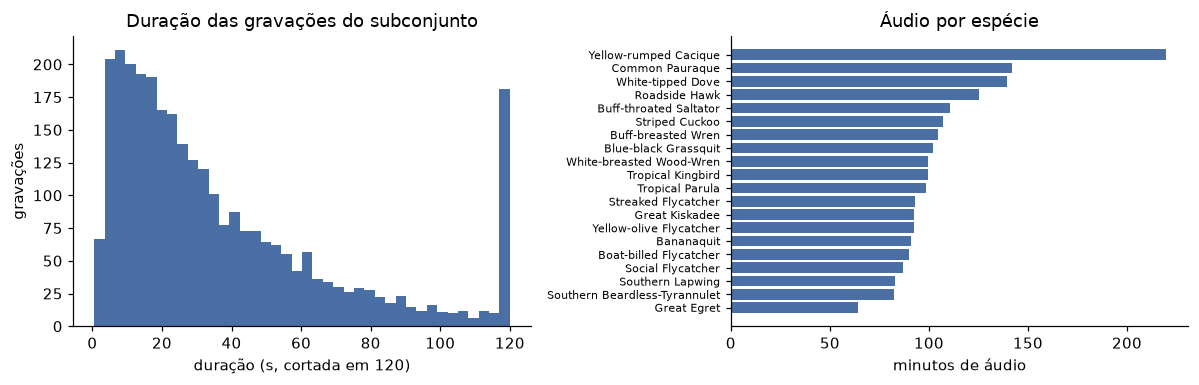

CPU times: total: 1.98 s
Wall time: 2.03 s


In [6]:
%%time
sub["duracao_s"] = dados.duracoes(sub).values
d = sub["duracao_s"]
print(f"total: {d.sum() / 3600:.1f} h | mediana {d.median():.1f} s | p90 {d.quantile(.9):.1f} s | máx {d.max():.0f} s")
print(f"gravações com menos de 5 s: {(d < 5).sum()}")
janelas = np.maximum(1, np.floor((d - 5) / 2.5) + 1)  # janelas de 5 s com 50% de sobreposição
print(f"janelas de 5 s (sobreposição 50%): {int(janelas.sum())}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(d.clip(upper=120), bins=40, color="#4a6fa5")
ax[0].set_xlabel("duração (s, cortada em 120)"); ax[0].set_ylabel("gravações"); ax[0].set_title("Duração das gravações do subconjunto")
por_esp = sub.groupby("common_name")["duracao_s"].sum().sort_values() / 60
ax[1].barh(por_esp.index, por_esp.values, color="#4a6fa5")
ax[1].set_xlabel("minutos de áudio"); ax[1].set_title("Áudio por espécie"); ax[1].tick_params(axis="y", labelsize=7)
fig.tight_layout(); fig.savefig(FIGS / "duracoes.png", bbox_inches="tight"); plt.show()

O número de gravações é igual entre espécies, mas o tempo de áudio não: algumas espécies têm gravações bem
mais longas e geram mais janelas. O desequilíbrio nas janelas é tratado no treino (amostragem ou limite de
janelas por gravação), e a métrica principal (F1-macro) dá o mesmo peso a cada espécie.

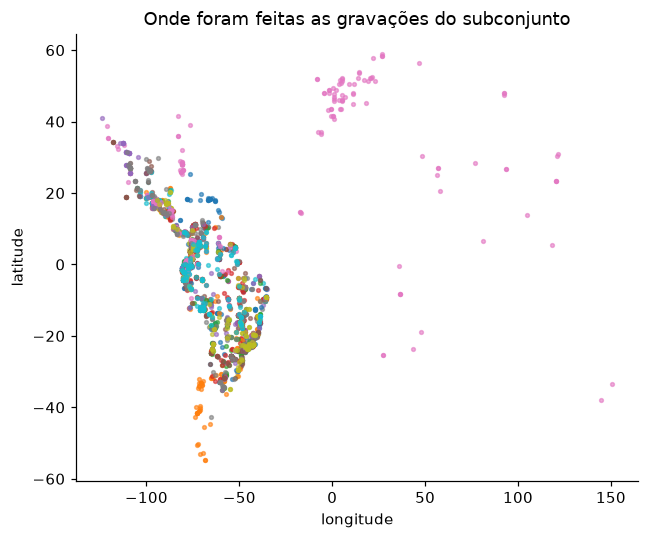

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
for esp, g in sub.groupby("common_name"):
    ax.scatter(g["longitude"], g["latitude"], s=6, alpha=0.6)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title("Onde foram feitas as gravações do subconjunto")
fig.tight_layout(); fig.savefig(FIGS / "mapa.png", bbox_inches="tight"); plt.show()

## Teste fixo e validação cruzada

In [8]:
div = dados.criar_divisoes(sub, frac_teste=0.2, k=5)
saida = dados.pasta_dados() / "subconjunto"; saida.mkdir(parents=True, exist_ok=True)
div.to_csv(saida / "divisoes.csv", index=False)
print(div["particao"].value_counts().to_string())
dados.resumo_divisoes(div)

particao
treino    2400
teste      600


col_0,fold 0,fold 1,fold 2,fold 3,fold 4,teste,total
primary_label,,,,,,,
banana,24,24,24,24,24,30,150
blbgra1,24,24,24,24,24,30,150
bobfly1,24,24,24,24,24,30,150
bubwre1,24,24,24,24,24,30,150
butsal1,24,24,24,24,24,30,150
compau,24,24,24,24,24,30,150
greegr,24,24,24,24,24,30,150
grekis,24,24,24,24,24,30,150
roahaw,24,24,24,24,24,30,150


Cada gravação está em exatamente uma partição. As janelas de 5 s criadas no pré-processamento herdam a
partição e o fold da gravação, então nenhuma gravação aparece ao mesmo tempo em treino e validação ou teste.